# Modeling: E0 baseline and E1 first fine-tune

**Milestone (30 Oct):** a YOLO model fine-tuned on our labelled cycle-ball frames, with a first result: **mAP50** and **mAP50-95**.

What this notebook does:

1. **Dataset:** a quick look at what we train on.
2. **E0, baseline:** score the ready-made COCO-pretrained YOLO on our val set, **with no training**. This is the "before".
3. **E1, fine-tune:** train the same model on our 60 train frames with default settings.
4. **Compare** per class and write down what we learned.

The "after minus before" difference is the *incremental delta*: proof that our labelling work helped. Rows E0 and E1 of the mAP log in [`README.md` §9](README.md#9-experiment-log-map-log) come from this notebook.

## 0. Setup

Framework: **Ultralytics YOLO11**, model size **s** (small). We use the same model for the baseline and the fine-tune, so the delta measures our data, not a model change.
Device: Apple GPU (`mps`) on a Mac, CUDA GPU (`0`) on Colab/Kaggle, otherwise CPU.

In [1]:
import shutil
from pathlib import Path

import torch
import ultralytics
import yaml
from IPython.display import Image, Markdown, display
from ultralytics import YOLO

ROOT = Path.cwd().parent                     # this notebook lives in modeling/
VERSION = "v1"                               # dataset version, part of every run name; change it together with DATA
DATA = ROOT / "data/cycle-ball-dataset"
RUNS = ROOT / "runs/modeling"                # all outputs go here (git-ignored)
MODEL = "yolo11s.pt"                         # COCO-pretrained YOLO11 small, downloaded on first use
DEVICE = "mps" if torch.backends.mps.is_available() else 0 if torch.cuda.is_available() else "cpu"

print("dataset", VERSION, "| ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device", DEVICE)

dataset v1 | ultralytics 8.4.192 | torch 2.15.0 | device mps


## 1. Dataset

73 frames from `cycle-ball.mp4` (1,170 frames in total), labelled by our data lead.

- **Split by time, not at random:** the first 80% of the video is train, the last 20% is val. Neighbouring frames are almost identical, so a random split would put near-copies of training frames into val and inflate mAP.
- **Classes:** `player` (the rider), `ball`, `bike`, `goal`. Rider and bike are separate boxes.
- Frames are **3024 × 1078** px, a wide panorama from a fixed camera. The referee is not labelled.

In [2]:
names = yaml.safe_load((DATA / "data.yaml").read_text())["names"]   # {0: 'player', 1: 'ball', 2: 'bike', 3: 'goal'}
W = 3024                                                             # all frames are 3024 x 1078

for split in ("train", "val"):
    rows = [l.split() for f in (DATA / "labels" / split).glob("*.txt") for l in f.read_text().splitlines() if l.strip()]
    counts = {n: sum(int(r[0]) == c for r in rows) for c, n in names.items()}
    ball_w = sorted(float(r[3]) * W for r in rows if names[int(r[0])] == "ball")
    n_img = len(list((DATA / "images" / split).glob("*.jpg")))
    print(f"{split:<5} images={n_img:<3} boxes={counts}  median ball width={ball_w[len(ball_w) // 2]:.0f} px")

train images=60  boxes={'player': 236, 'ball': 60, 'bike': 227, 'goal': 120}  median ball width=36 px
val   images=13  boxes={'player': 52, 'ball': 13, 'bike': 52, 'goal': 26}  median ball width=28 px


**Why the ball will be the hard class.** YOLO shrinks each frame so that its long side equals `imgsz`. At the default `imgsz=640`, a 3024 px wide frame shrinks **4.7×**, so a ~28 px ball becomes **~6 px**. YOLO's finest detection grid has a cell every **8 px** (stride 8). During training, a box only gets positive training examples from grid points that fall *inside* it. A ball smaller than 8 px often contains no grid point, so the model gets no training signal from it at all. At `imgsz=1280` the same ball is ~12 px and always contains one. So we expect the ball to be the weakest class at 640. The image-size experiment (E2) tests 1280.

**Small val set:** 13 val frames means 13 balls, so finding one more ball moves ball AP by about 8 points. Small differences between runs are noise.

## 2. E0: baseline, pretrained YOLO with no training

The pretrained model was trained on **COCO** (80 everyday object classes). Three of them match ours one-to-one:

| Ours | COCO id | COCO name |
|---|---|---|
| player | 0 | person |
| bike | 1 | bicycle |
| ball | 32 | sports ball |
| goal | — | *(no COCO class)* |

`yolo val` compares predictions and labels by **class id**, and our ids (ball = 1) are not COCO's (ball = 32). So we make a **copy of the val set** with the ids translated to COCO's. `goal` has no COCO class, so its boxes are dropped from the copy. E0 is scored on player, bike and ball only. The real dataset is not touched.

AP is computed only for classes that appear in the labels, so the pretrained model's other 77 classes (chairs, bottles…) don't affect the score.

**Hypothesis:** `player` and `bike` are found reasonably well, since people and bicycles are common in COCO. `ball` is poor: COCO balls are mostly large and close up, while ours is tiny, blurred and often touching a wheel. The unlabelled referee and spectators will be boxed as `person` and count as false positives for `player`.

In [3]:
TO_COCO = {"player": 0, "bike": 1, "ball": 32}     # goal has no COCO class -> dropped
coco_names = YOLO(MODEL).names                      # the 80 COCO class names, {id: name}

base = RUNS / f"E0_data_{VERSION}"                  # remapped copy of val
for sub in ("images/val", "labels/val"):
    (base / sub).mkdir(parents=True, exist_ok=True)
for img in (DATA / "images/val").glob("*.jpg"):
    shutil.copy(img, base / "images/val" / img.name)
    rows = [l.split() for l in (DATA / "labels/val" / f"{img.stem}.txt").read_text().splitlines() if l.strip()]
    keep = [" ".join([str(TO_COCO[names[int(c)]]), *box]) for c, *box in rows if names[int(c)] in TO_COCO]
    (base / "labels/val" / f"{img.stem}.txt").write_text("\n".join(keep))
(base / "data.yaml").write_text(yaml.safe_dump({"path": str(base), "train": "images/val", "val": "images/val", "names": coco_names}))
print("E0 val copy:", base)

E0 val copy: /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_data_v1


Run validation at two image sizes. The table printed for each run lists every class: `Instances` = number of labelled boxes, `P` / `R` = precision / recall, then mAP50 and mAP50-95.

In [4]:
def per_class(r):
    # {our class name: (AP50, AP50-95)} from a val result; COCO names are translated to ours
    ours = {"person": "player", "bicycle": "bike", "sports ball": "ball"}
    return {ours.get(r.names[c], r.names[c]): (r.box.ap50[i], r.box.ap[i]) for i, c in enumerate(r.box.ap_class_index)}

results = {}
for imgsz in (640, 1280):
    r = YOLO(MODEL).val(data=str(base / "data.yaml"), imgsz=imgsz, device=DEVICE, project=str(RUNS), name=f"E0_{imgsz}_{VERSION}", exist_ok=True)
    results[f"E0 @{imgsz}"] = per_class(r)

Ultralytics 8.4.192 🚀 Python-3.14.8 torch-2.15.0 MPS (Apple M4)


YOLO11s summary (fused): 100 layers, 9,443,760 parameters, 0 gradients, 21.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8414.7±1063.7 MB/s, size: 299.2 KB)


val: Scanning /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_data_v1/labels/val... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 3.3Kit/s 0.0s

val: New cache created: /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_data_v1/labels/val.cache


...

                person         13         52      0.126      0.846       0.16     0.0978


               bicycle         13         52      0.964      0.731      0.803      0.579


           sports ball         13         13          1      0.878      0.925      0.663


Speed: 0.3ms preprocess, 35.7ms inference, 0.0ms loss, 1.9ms postprocess per image


Results saved to /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E0_1280_v1


**Ball at 640: recall 0 but AP50 0.73. How?** `P` and `R` in the table are measured at a single confidence threshold, the one where YOLO gets the best average F1 over all classes. AP is computed over *all* thresholds and only depends on how the boxes are *ranked* by confidence. The check below lists, for every val frame, the confidence of the pretrained model's best `sports ball` box that overlaps the labelled ball (IoU ≥ 0.5).

In [5]:
from ultralytics.utils.metrics import box_iou

m = YOLO(MODEL)
for img in sorted((base / "images/val").glob("*.jpg")):
    rows = [l.split() for l in (base / "labels/val" / f"{img.stem}.txt").read_text().splitlines()]
    x, y, w, h = (float(v) for v in next(r for r in rows if r[0] == "32")[1:])   # the labelled ball
    res = m.predict(img, imgsz=640, conf=0.001, classes=[32], device=DEVICE, verbose=False)[0]
    ih, iw = res.orig_shape
    gt = torch.tensor([[(x - w / 2) * iw, (y - h / 2) * ih, (x + w / 2) * iw, (y + h / 2) * ih]])
    boxes = res.boxes.cpu()
    conf = boxes.conf[box_iou(gt, boxes.xyxy)[0] >= 0.5] if len(boxes) else torch.empty(0)
    print(f"{img.stem}: " + (f"found, confidence {conf.max():.3f}" if len(conf) else "not found"))

frame_00960: not found
frame_00973: not found
frame_01006: found, confidence 0.055
frame_01029: found, confidence 0.048
frame_01039: found, confidence 0.056
frame_01072: found, confidence 0.017
frame_01092: found, confidence 0.040
frame_01113: found, confidence 0.023
frame_01127: found, confidence 0.023
frame_01139: found, confidence 0.008
frame_01140: found, confidence 0.009
frame_01152: found, confidence 0.004


frame_01167: found, confidence 0.002


## 3. E1: fine-tune on our frames

**What fine-tuning changes:** the pretrained model's last layer (the *head*) outputs 80 COCO classes. Ultralytics replaces it with a fresh head for our 4 classes. The rest of the network (the *backbone*, which extracts features, and the *neck*, which combines them) starts from the COCO weights and is adjusted on our 60 frames. Starting from COCO is what makes 60 images enough: the model already knows edges, shapes, people and bicycles.

**Settings: Ultralytics defaults**, so E1 is the reference later experiments are compared against. 100 epochs, automatic optimizer (AdamW for short runs like ours), default augmentation (mosaic, left-right flips, colour and scale jitter), mosaic switched off for the last 10 epochs, and `best.pt` saved at the best validation epoch. `seed=0` for repeatability (on `mps`, runs may still differ slightly).

**Hypothesis:** a large gain over E0 on every class, biggest on `ball` and `player`. The ball stays the weakest class, because at 640 it is only ~6 px.

**Image size 1280 (experiment E2) is not run here.** We tried it on the Mac (Apple M4, 16 GB shared memory). It ran out of memory and swapped: about 12 minutes per batch, i.e. days for 100 epochs. E2 runs on a Colab GPU instead.

If `best.pt` already exists, training is skipped and only validation runs, so re-running the notebook doesn't retrain (~30 min on the Mac). Delete the run folder to train again.

In [6]:
name = f"E1_640_{VERSION}"
best = RUNS / name / "weights/best.pt"
if not best.exists():
    YOLO(MODEL).train(data=str(DATA / "data.yaml"), imgsz=640, seed=0, device=DEVICE, project=str(RUNS), name=name, exist_ok=True)
r = YOLO(best).val(data=str(DATA / "data.yaml"), imgsz=640, device=DEVICE, project=str(RUNS), name=f"{name}_val", exist_ok=True)
results["E1 @640"] = per_class(r)

Ultralytics 8.4.192 🚀 Python-3.14.8 torch-2.15.0 MPS (Apple M4)


YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9308.8±1664.0 MB/s, size: 298.9 KB)


val: Scanning /Users/artem/University/DeepLearning/computer-vision/data/cycle-ball-dataset/labels/val.cache... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 13.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.4it/s 0.2s

...

                  ball         13         13      0.992          1      0.995      0.697


                  bike         13         52      0.973      0.673      0.818      0.496


                  goal         13         26      0.984          1      0.995      0.971


Speed: 1.1ms preprocess, 6.7ms inference, 0.0ms loss, 1.2ms postprocess per image


Results saved to /Users/artem/University/DeepLearning/computer-vision/runs/modeling/E1_640_v1_val


## 4. Training curves

Top row: training losses. Bottom row: validation losses and metrics. How to read them:

- `box_loss`: how far predicted boxes are from the labelled ones. `cls_loss`: how wrong the class guess is. `dfl_loss`: how precisely box edges are placed. All should go **down**.
- Train and val loss both falling means it's learning. Train falling while val rises means **overfitting** (`best.pt` is already saved from the best epoch).
- A drop in the last 10 epochs is normal: that's when mosaic is switched off.
- Jumpy val metrics are expected with only 13 val frames.

Prediction images (`val_batch*_pred.jpg`) contain video frames, so they are **not embedded here** (the repo is public). Open them in `runs/modeling/E1_*/`.

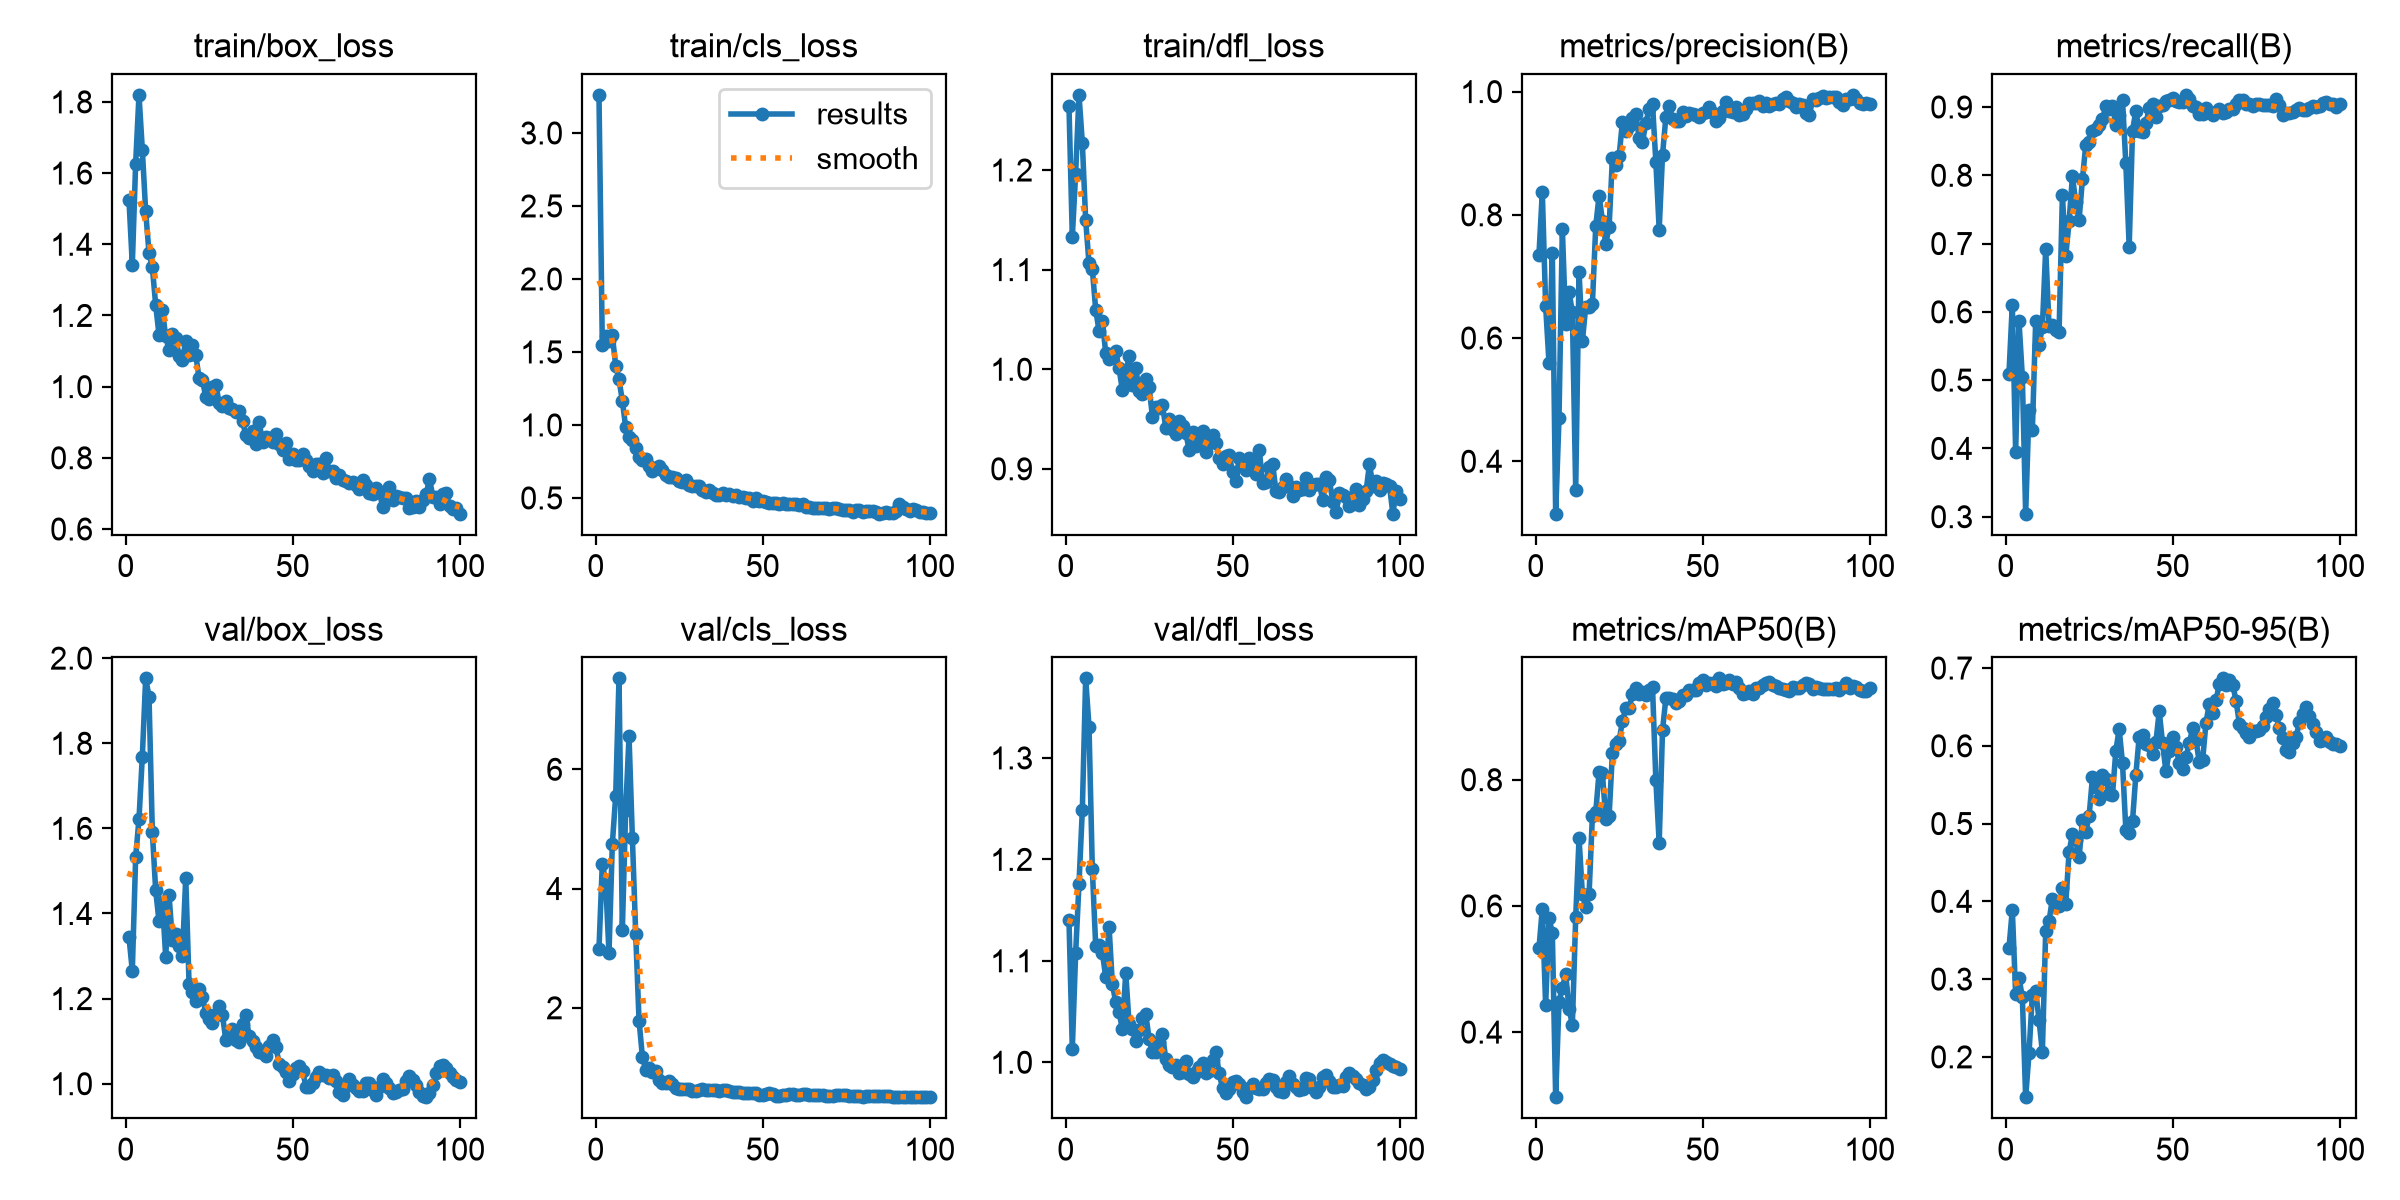

In [7]:
display(Image(filename=str(RUNS / f"E1_640_{VERSION}/results.png"), width=900))

## 5. Comparison

Each cell is **AP50 / AP50-95**. Only `ball` is a fully like-for-like comparison: we added data for it, and its box means the same thing in COCO and in our labels. `player` and `bike` are close too, since they map one-to-one to COCO, but the pretrained model has never seen our camera.

- **mean (ball, player, bike):** the fair mean, over the classes every run has.
- **mAP, all classes in the run:** what YOLO itself reports. For E1 this includes `goal`, which is easy: the camera is fixed, so the goals never move. It pushes the number up and isn't comparable with E0.

In [8]:
shared = ["ball", "player", "bike"]

def mean(v, classes, k):
    return sum(v[c][k] for c in classes) / len(classes)

lines = ["| class (AP50 / AP50-95) | " + " | ".join(results) + " |", "|---" * (len(results) + 1) + "|"]
for c in ["ball", "player", "bike", "goal"]:
    lines.append(f"| {c} | " + " | ".join(f"{v[c][0]:.3f} / {v[c][1]:.3f}" if c in v else "—" for v in results.values()) + " |")
lines.append("| **mean (ball, player, bike)** | " + " | ".join(f"**{mean(v, shared, 0):.3f} / {mean(v, shared, 1):.3f}**" for v in results.values()) + " |")
lines.append("| mAP, all classes in the run | " + " | ".join(f"{mean(v, list(v), 0):.3f} / {mean(v, list(v), 1):.3f}" for v in results.values()) + " |")
display(Markdown("\n".join(lines)))

| class (AP50 / AP50-95) | E0 @640 | E0 @1280 | E1 @640 |
|---|---|---|---|
| ball | 0.727 / 0.468 | 0.925 / 0.663 | 0.995 / 0.697 |
| player | 0.176 / 0.088 | 0.160 / 0.098 | 0.935 / 0.583 |
| bike | 0.673 / 0.389 | 0.803 / 0.579 | 0.818 / 0.496 |
| goal | — | — | 0.995 / 0.971 |
| **mean (ball, player, bike)** | **0.525 / 0.315** | **0.629 / 0.447** | **0.916 / 0.592** |
| mAP, all classes in the run | 0.525 / 0.315 | 0.629 / 0.447 | 0.936 / 0.687 |

## 6. Conclusions (dataset v1)

**Milestone result:** E1 (YOLO11s fine-tuned with default settings, `imgsz=640`) reaches **mAP50 = 0.936** and **mAP50-95 = 0.687** on val, over all 4 classes as YOLO reports it. On the 3 classes that E0 can be compared on, at the same image size, it goes from **0.525 → 0.916 mAP50** and **0.315 → 0.592 mAP50-95**.

**Per class (AP50, E0 @640 → E1 @640):**
- **ball: 0.727 → 0.995.** E0's AP is misleading. The pretrained model finds 11 of the 13 balls with well-placed boxes, but with confidence of only ~0.002–0.06 (check above). AP only measures ranking, so it looks fine, but at any usable threshold (e.g. the default 0.25) the pretrained model finds **no** balls (R = 0 in the table). After fine-tuning, all 13 are found (R = 1.0) with high confidence.
- **player: 0.176 → 0.935.** The biggest gain. E0's precision is only 0.18. The prediction images (`runs/modeling/E0_640_v1/val_batch*_pred.jpg`) show why: COCO `person` boxes the people at the officials' table in the foreground (confidence 0.6–0.8 in every frame), spectators behind the boards and the referee. None of them is a player. Fine-tuning taught the model "player = rider on the court".
- **bike: 0.673 → 0.818.** The weakest class after fine-tuning (recall 0.67). Bikes overlap each other and the riders, and 11 training frames have fewer than 4 bikes labelled, so a partly hidden bike is taught as background. Feedback for data cleaning.
- **goal: 0.995 / 0.971.** Easy because the camera is fixed. It raises the all-class mAP, which is why we also report the 3-class mean.

**Hypotheses vs. results:**
- E0 "player and bike fine, ball poor": **partly wrong.** Bike was fine. The ball was located but never confidently. **Player was the worst class**, because of all the non-player people in the frame.
- E1 "ball stays the weakest class at 640 (~6 px)": **refuted.** Ball AP50 is 0.995. Its AP50-95 (0.697) shows the boxes are not yet pixel-precise, which is where a larger image could still help.
- Image size clearly matters for the pretrained model: E0 ball AP50 goes 0.727 → 0.925 and bike AP50-95 goes 0.389 → 0.579 from 640 to 1280. Bike AP50-95 at 1280 is even higher than after fine-tuning at 640 (0.496). That makes E2 (fine-tune at 1280) the most promising next experiment.

**Limits:** val is 13 frames from the same match, camera and video (its last 20%). One ball is worth ~8 AP points, and this is a single run with one seed. The scores show the model works on this video, not that it generalises to other matches.

**For the app (D):** inference takes ~8 ms per frame at 640 on the Mac's GPU (M4, `mps`). E0 at 1280 took ~34 ms. Model: `runs/modeling/E1_640_v1/weights/best.pt`.

**Next:**
- Fix the one wrong label (`frame_00749`: a person behind the boards labelled as `player`), export dataset v2, and re-run E0 and the best E1 on it.
- Train the better E1 config with 3 seeds and report mean ± std. With 13 val balls, one run isn't evidence.
- E2, image size 1280, on a Colab GPU (too big for the Mac). Then E3–E6 from [`README.md` §5](README.md#5-experiment-plan): frozen layers, augmentations, epochs, model size.
- Idea: frames are 2.8:1, so most of a square training input is padding and dark stands. Cropping to the court would make the ball bigger at the same `imgsz`.